#### Цель
Решить задачу многоклассовой классификации: по информации о студенте, известной при поступлении, предсказать один из исходов обучения — Dropout, Enrolled или Graduate — и понять, кому стоит предложить раннюю поддержку.
#### Данные
Используй Predict Students' Dropout and Academic Success от UCI: 4 424 записи, 36 признаков смешанного типа и три несбалансированных класса цели Target.
В частях I–II достаточно Jupyter-ноутбука. Все три части можно вести в одном репозитории, сохраняя результат каждой на отдельной ветке: clf/students_dropout/part_1, clf/students_dropout/part_2, clf/students_dropout/part_3. Для этой задачи точка предсказания — момент поступления: в модель можно включать только признаки, которые уже известны тогда. Сырые данные не коммить в репозиторий.
#### Задание
1. Временная граница: составь allowlist признаков по документации UCI. Все показатели Curricular units 1st sem ... и Curricular units 2nd sem ... исключи: они появляются после поступления и для раннего прогноза являются будущей информацией. Зафиксируй этот список и его обоснование в ноутбуке.
2. EDA: изучи размеры и типы данных, распределение классов Dropout / Enrolled / Graduate, пропуски, дубликаты и возможные категориальные коды, записанные числами. Объясни, почему надо смотреть на качество по каждому классу, а не только на Accuracy.
3. Подготовка: сделай стратифицированный train/test split с фиксированным random_state. Построй pipeline, в котором кодирование категориальных признаков, масштабирование числовых и другие обучаемые преобразования fitятся только на train.
4. Модели: обучи многоклассовую логистическую регрессию и решающее дерево. Для каждой модели выведи classification report, balanced accuracy и confusion matrix.
5. Сравнение: сведи результаты в таблицу и выбери модель главным образом по macro F1. Объясни, что значит ошибка Dropout ↔ Graduate и как результаты могут использоваться для приглашения студента на консультацию, а не для автоматического наказания или отказа.
#### Другое
* Не превращай коды категорий в непрерывные величины без проверки их смысла в документации датасета.
* Можно дополнительно показать многоклассовый ROC-AUC в схеме one-vs-rest, но он не заменяет метрики по каждому классу.

#### 1. Библиотеки и модули

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile
import hashlib
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20
CLASS_ORDER = ["Dropout", "Enrolled", "Graduate"]
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 45)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
# Незавершённая оптимизация не должна остаться незамеченной.
warnings.filterwarnings("error", category=ConvergenceWarning)
print({"Python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "matplotlib": matplotlib.__version__})

{'Python': '3.12.2', 'numpy': '2.5.2', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1'}


In [2]:
DATA_PATH = Path("data/raw/data.csv")
DATA_URL = (
    "https://archive.ics.uci.edu/static/public/697/"
    "predict+students+dropout+and+academic+success.zip"
)
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    try:
        with urlopen(DATA_URL, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(BytesIO(archive_bytes)) as archive:
            # Читаем только нужный файл, не распаковываем произвольные пути.
            csv_bytes = archive.read("data.csv")
        DATA_PATH.write_bytes(csv_bytes)
    except Exception as exc:
        raise RuntimeError(
            "Не удалось скачать UCI. Скачать архив со страницы датасета "
            "и поместить data.csv в data/raw/, затем повторить запуск."
        ) from exc

print("SHA-256 исходного CSV:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
df = pd.read_csv(DATA_PATH, sep=";")
# В исходном имени Daytime/evening attendance присутствует табуляция.
df.columns = df.columns.str.strip()
assert df.columns.is_unique, "После очистки обнаружены совпадающие названия столбцов"
assert df.shape == (4424, 37), f"Неожиданная версия данных: {df.shape}"
assert df["Target"].notna().all()
assert set(df["Target"].unique()) == set(CLASS_ORDER)
print(f"Строк: {len(df):,}; признаков: {df.shape[1] - 1}; целевых столбцов: 1")

SHA-256 исходного CSV: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae
Строк: 4,424; признаков: 36; целевых столбцов: 1


#### 2. Временная граница и фиксированный allowlist¶
Признак допустим, если его значение относится к моменту поступления и могло быть получено тогда (даже с высокой предсказательностью признака).  
Все 12 полей Curricular units 1st sem ... и Curricular units 2nd sem ... исключены, включая credited и enrolled, как требует условие. Их значения из семестровой выгрузки не используются даже косвенно при отборе признаков.  
Выбираем консервативный набор из 18 признаков. Основание - смысл полей и кодов в словаре UCI. Для анкетных характеристик принимается заявленное UCI описание данных при поступлении. Это учебное допущение: CSV не содержит временных меток обновления анкет, поэтому в реальной системе потребуется архивный снимок на дату поступления.  
Дополнительно не допускаем шесть полей с недостаточно определённым моментом доступности: Debtor, Tuition fees up to date, Scholarship holder, Unemployment rate, Inflation rate, GDP.

In [3]:
# Явный allowlist: новые поля из будущих выгрузок не попадут в модель автоматически.
FEATURE_SPEC = [
    ("Marital status", "category", "Семейное положение из анкеты; код не является числом на шкале"),
    ("Application mode", "category", "Способ поступления известен при оформлении"),
    ("Application order", "category", "Приоритет программы в заявлении; интервалы не считаем равными"),
    ("Course", "category", "Программа, на которую поступил студент; число является идентификатором"),
    ("Daytime/evening attendance", "category", "Выбранная дневная или вечерняя форма"),
    ("Previous qualification", "category", "Предыдущее образование; коды не образуют числовую шкалу"),
    ("Previous qualification (grade)", "numeric", "Оценка предыдущего образования, шкала 0–200"),
    ("Nacionality", "category", "Гражданство из анкеты; сохранено исходное написание UCI"),
    ("Mother's qualification", "category", "Образование матери из анкеты; номинальные коды"),
    ("Father's qualification", "category", "Образование отца из анкеты; номинальные коды"),
    ("Mother's occupation", "category", "Профессия матери, указанная при поступлении"),
    ("Father's occupation", "category", "Профессия отца, указанная при поступлении"),
    ("Admission grade", "numeric", "Вступительный балл, шкала 0–200"),
    ("Displaced", "category", "Анкетный статус переезда к месту обучения на дату поступления"),
    ("Educational special needs", "category", "Заявленные при поступлении особые образовательные потребности"),
    ("Gender", "category", "Пол, записанный в анкете; коды UCI"),
    ("Age at enrollment", "numeric", "Возраст непосредственно при поступлении"),
    ("International", "category", "Международный статус при поступлении"),
]
feature_spec = pd.DataFrame(FEATURE_SPEC, columns=["Признак", "Обработка", "Обоснование"])
ALLOWLIST = feature_spec["Признак"].tolist()
CAT_FEATURES = feature_spec.loc[feature_spec["Обработка"].eq("category"), "Признак"].tolist()
NUM_FEATURES = feature_spec.loc[feature_spec["Обработка"].eq("numeric"), "Признак"].tolist()
UNCERTAIN_FEATURES = [
    "Debtor", "Tuition fees up to date", "Scholarship holder",
    "Unemployment rate", "Inflation rate", "GDP",
]
SEMESTER_FEATURES = [c for c in df if c.startswith("Curricular units ")]
assert len(SEMESTER_FEATURES) == 12
assert len(ALLOWLIST) == 18 and len(set(ALLOWLIST)) == 18
assert set(ALLOWLIST).isdisjoint(SEMESTER_FEATURES + UNCERTAIN_FEATURES + ["Target"])
assert set(df.columns) == set(ALLOWLIST + SEMESTER_FEATURES + UNCERTAIN_FEATURES + ["Target"])
display(feature_spec)
print("Исключённые семестровые поля:")
print("\n".join(SEMESTER_FEATURES))

,Признак,Обработка,Обоснование
0,Marital status,category,Семейное положение из анкеты; код не является числом на шкале
1,Application mode,category,Способ поступления известен при оформлении
2,Application order,category,Приоритет программы в заявлении; интервалы не считаем равными
3,Course,category,"Программа, на которую поступил студент; число является идентификатором"
4,Daytime/evening attendance,category,Выбранная дневная или вечерняя форма
5,Previous qualification,category,Предыдущее образование; коды не образуют числовую шкалу
6,Previous qualification (grade),numeric,"Оценка предыдущего образования, шкала 0–200"
7,Nacionality,category,Гражданство из анкеты; сохранено исходное написание UCI
8,Mother's qualification,category,Образование матери из анкеты; номинальные коды
9,Father's qualification,category,Образование отца из анкеты; номинальные коды


Исключённые семестровые поля:
Curricular units 1st sem (credited)
Curricular units 1st sem (enrolled)
Curricular units 1st sem (evaluations)
Curricular units 1st sem (approved)
Curricular units 1st sem (grade)
Curricular units 1st sem (without evaluations)
Curricular units 2nd sem (credited)
Curricular units 2nd sem (enrolled)
Curricular units 2nd sem (evaluations)
Curricular units 2nd sem (approved)
Curricular units 2nd sem (grade)
Curricular units 2nd sem (without evaluations)


#### 3. Аудит исходной таблицы
До split проверяем схему, пропуски, полные дубликаты и распределение цели. Эти проверки не обучают преобразования. Связи признаков с целью и распределения для анализа далее рассматриваем на train.  
int64 — тип хранения, а не семантический тип. Номер программы и код профессии нельзя автоматически подавать как непрерывные величины. Повторы одинакового профиля разных студентов не обязательно являются дубликатами людей, ведь идентификатора студента здесь нет.

,dtype,missing,n_unique,Использование
Marital status,int64,0,6,категориальный
Application mode,int64,0,18,категориальный
Application order,int64,0,8,категориальный
Course,int64,0,17,категориальный
Daytime/evening attendance,int64,0,2,категориальный
Previous qualification,int64,0,17,категориальный
Previous qualification (grade),float64,0,101,числовой
Nacionality,int64,0,21,категориальный
Mother's qualification,int64,0,29,категориальный
Father's qualification,int64,0,34,категориальный


Всего NaN: 0
Бесконечные значения: 0
Полные дубликаты строк: 0
Повторы по allowlist: 0


,Количество,"Доля, %"
Target,,
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


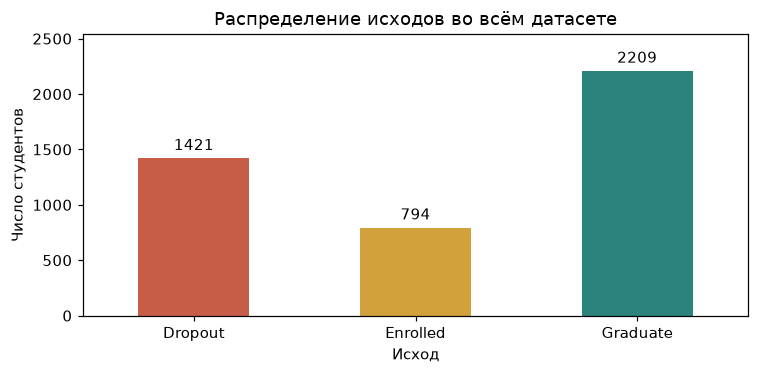

In [ ]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(dropna=False),
})
schema["Использование"] = [
    "категориальный" if c in CAT_FEATURES else
    "числовой" if c in NUM_FEATURES else
    "цель" if c == "Target" else "исключён"
    for c in schema.index
]
display(schema)
print("Всего NaN:", int(df.isna().sum().sum()))
print("Бесконечные значения:", int(np.isinf(df.select_dtypes(include=np.number)).sum().sum()))
print("Полные дубликаты строк:", int(df.duplicated().sum()))
print("Повторы по allowlist:", int(df.duplicated(subset=ALLOWLIST).sum()))
# Если повторы появятся, сначала выясняем происхождение,
# затем выбираем дедупликацию или групповой split; не удаляем просто молча.
assert not df.duplicated().any(), "Нужно решить вопрос полных дубликатов до split"
assert not df.duplicated(subset=ALLOWLIST).any(), "Нужен анализ одинаковых профилей до split"
assert not np.isinf(df.select_dtypes(include=np.number)).any().any()

class_counts = df["Target"].value_counts().reindex(CLASS_ORDER)
class_table = pd.DataFrame({"Количество": class_counts, "Доля, %": class_counts / len(df) * 100})
display(class_table.round(2))
ax = class_counts.plot.bar(color=["#C75D47", "#D3A13B", "#2C827C"], figsize=(7, 3.5), rot=0)
ax.set(title="Распределение исходов во всём датасете", xlabel="Исход", ylabel="Число студентов")
for container in ax.containers:
    ax.bar_label(container, padding=3)
ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

Если всегда предсказывать Graduate, Accuracy будет почти 50%, но Recall двух других классов будет равен нулю. Поэтому основная метрика — macro F1, среднее F1 трёх классов с одинаковым весом.  
Для каждого класса остальные два считаются отрицательными. Precision показывает, какая доля предсказаний класса верна; Recall — какую долю реальных представителей класса нашли. Balanced accuracy — средний Recall трёх классов. В этой задаче он совпадает с macro avg / recall в classification report. Weighted F1 и Accuracy сильнее зависят от многочисленного класса.

#### 4. Стратифицированный train/test split
20% наблюдений откладываем до финальной оценки. Стратификация сохраняет близкие доли трёх исходов. Для выбора между моделями используем 5-fold CV только на train, затем обучаем обе модели на всём train и оцениваем на test один раз. Лучшая фиксируется до просмотра test.  
Случайный split оценивает качество на похожей совокупности студентов. Он не доказывает перенос на будущие годы или другой вуз: для этого нужны временной и внешний тесты, а в CSV нет подходящих идентификаторов когорт.

In [5]:
X = df.loc[:, ALLOWLIST].copy()
y = df["Target"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE,
)
assert X_train.index.intersection(X_test.index).empty
assert set(X_train.columns) == set(ALLOWLIST)
split_table = pd.concat({
    "Все": y.value_counts().reindex(CLASS_ORDER),
    "Train": y_train.value_counts().reindex(CLASS_ORDER),
    "Test": y_test.value_counts().reindex(CLASS_ORDER),
}, axis=1)
split_table["Train, %"] = split_table["Train"] / len(y_train) * 100
split_table["Test, %"] = split_table["Test"] / len(y_test) * 100
display(split_table.round(2))
print("Train:", X_train.shape, "Test:", X_test.shape)

,Все,Train,Test,"Train, %","Test, %"
Target,,,,,
Dropout,1421,1137,284,32.13,32.09
Enrolled,794,635,159,17.94,17.97
Graduate,2209,1767,442,49.93,49.94


Train: (3539, 18) Test: (885, 18)


#### 5. EDA на обучающей части
В Application order порядок от 0 до 9. Мы используем one-hot: это сохраняет категории без предположения о линейном влиянии каждого следующего приоритета. Образование родителей тоже кодируем one-hot: числовые коды не являются последовательными уровнями образования.  
Важное различие: в CSV может не быть NaN, но словарь содержит смысловые пропуски — например, 34 в образовании родителей означает неизвестное значение, а 99 в профессии — пустую запись. Сохраняем их отдельными категориями (а не заменяем произвольным уровнем образования или профессией), т.е. 0 не считаем универсальным обозначением пропуска.

In [6]:
category_audit = pd.DataFrame({
    "Уникальных на train": X_train[CAT_FEATURES].nunique(),
    "Коды на train": [sorted(X_train[c].dropna().unique().tolist()) for c in CAT_FEATURES],
})
display(category_audit)
semantic_missing = pd.DataFrame([
    {"Признак": c, "Код": value, "Смысл": meaning,
     "Количество на train": int(X_train[c].eq(value).sum())}
    for c, value, meaning in [
        ("Mother's qualification", 34, "Неизвестно"),
        ("Father's qualification", 34, "Неизвестно"),
        ("Mother's occupation", 99, "Пустая запись"),
        ("Father's occupation", 99, "Пустая запись"),
    ]
])
display(semantic_missing)
display(X_train[NUM_FEATURES].describe().T.round(2))
for c in ["Admission grade", "Previous qualification (grade)"]:
    assert X_train[c].dropna().between(0, 200).all(), f"Проверьте диапазон {c}"
assert X_train["Age at enrollment"].dropna().gt(0).all()

,Уникальных на train,Коды на train
Marital status,6,"[1, 2, 3, 4, 5, 6]"
Application mode,18,"[1, 2, 5, 7, 10, 15, 16, 17, 18, 26, 27, 39, 42, 43, 44, 51, 53, 57]"
Application order,8,"[0, 1, 2, 3, 4, 5, 6, 9]"
Course,17,"[33, 171, 8014, 9003, 9070, 9085, 9119, 9130, 9147, 9238, 9254, 9500, 9556, 9670, 9773, 9853, 9991]"
Daytime/evening attendance,2,"[0, 1]"
Previous qualification,17,"[1, 2, 3, 4, 5, 6, 9, 10, 12, 14, 15, 19, 38, 39, 40, 42, 43]"
Nacionality,19,"[1, 2, 6, 11, 13, 14, 21, 22, 24, 25, 26, 32, 41, 62, 100, 101, 103, 105, 108]"
Mother's qualification,28,"[1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 14, 18, 19, 22, 26, 29, 30, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]"
Father's qualification,32,"[1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 14, 18, 19, 20, 22, 25, 26, 27, 29, 30, 31, 34, 35, 36, 37, 38, 39, 40, ..."
Mother's occupation,31,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 90, 99, 122, 123, 131, 132, 134, 141, 143, 144, 151, 152, 153, 171, 173..."


,Признак,Код,Смысл,Количество на train
0,Mother's qualification,34,Неизвестно,108
1,Father's qualification,34,Неизвестно,93
2,Mother's occupation,99,Пустая запись,14
3,Father's occupation,99,Пустая запись,16


,count,mean,std,min,25%,50%,75%,max
Previous qualification (grade),3539.0,132.68,13.20,95.0,125.0,133.1,140.0,190.0
Admission grade,3539.0,126.88,14.53,95.0,117.8,126.0,134.9,190.0
Age at enrollment,3539.0,23.25,7.61,17.0,19.0,20.0,25.0,70.0


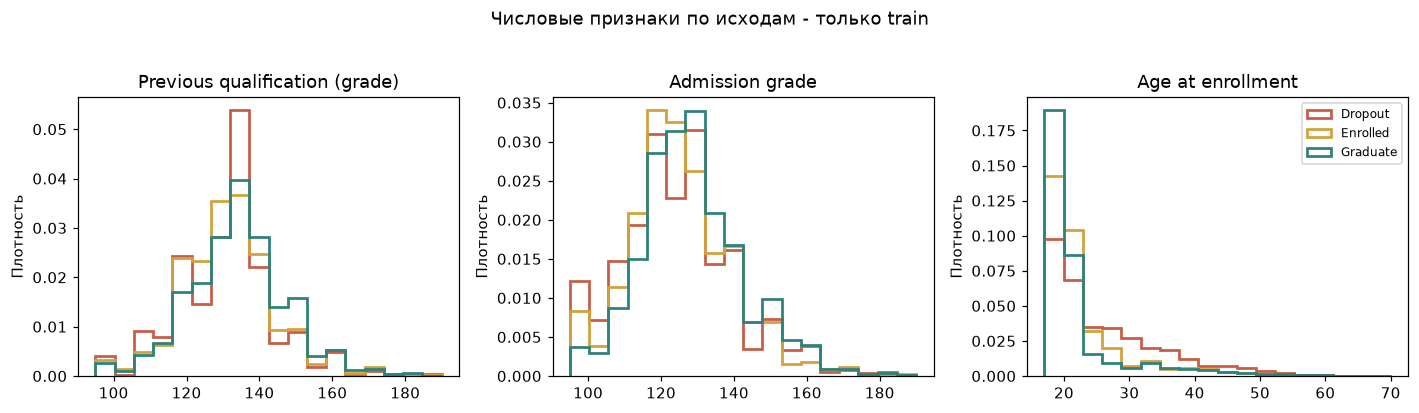

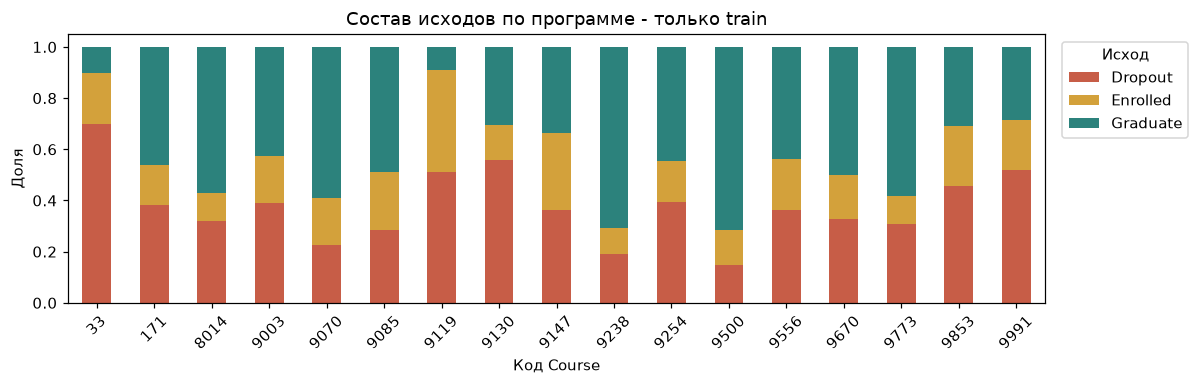

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = ["#C75D47", "#D3A13B", "#2C827C"]
for ax, column in zip(axes, NUM_FEATURES):
    # Одинаковые интервалы для классов, плотность устраняет влияние их размера.
    bins = np.histogram_bin_edges(X_train[column].dropna(), bins=18)
    for label, color in zip(CLASS_ORDER, colors):
        values = X_train.loc[y_train.eq(label), column].dropna()
        ax.hist(values, bins=bins, density=True, histtype="step", linewidth=1.8,
                label=label, color=color)
    ax.set(title=column, ylabel="Плотность")
axes[-1].legend(fontsize=8)
fig.suptitle("Числовые признаки по исходам - только train", y=1.03)
plt.tight_layout()
plt.show()

course_counts = pd.crosstab(X_train["Course"], y_train).reindex(columns=CLASS_ORDER, fill_value=0)
course_shares = course_counts.div(course_counts.sum(axis=1), axis=0)
ax = course_shares.plot.bar(stacked=True, color=colors, figsize=(11, 3.6), rot=45)
ax.set(title="Состав исходов по программе - только train", xlabel="Код Course", ylabel="Доля")
ax.legend(title="Исход", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Распределения классов перекрываются: один балл или возраст не задаёт исход однозначно. Различия между программами могут отражать отбор абитуриентов, условия обучения и другие факторы - это так думаем, а не точная причина прекращения обучения. Возрастные хвосты не удаляем автоматически: взрослые студенты могут быть реальными.

#### 6. Предобработка внутри pipeline
Для 15 категориальных признаков: заполнение настоящих NaN самым частым значением → one-hot. Для 3 числовых: заполнение медианой → StandardScaler. Сейчас NaN нет, но pipeline определяет поведение при их появлении.  
handle_unknown="ignore" позволяет обработать категорию, которой не было на обучающем фолде; её one-hot блок будет нулевым. Медианы, категории и параметры масштабирования определяются заново внутри каждого CV train-fold. Для дерева масштабирование не требуется, однако одинаковое преобразование числовых шкал не меняет порядок наблюдений и удобно для сравнения.  
remainder="drop" дополнительно блокирует поля вне списков. До разделения данных нет вызовов fit или fit_transform.

In [8]:
def make_preprocessor():
    """Создать новый независимый преобразователь для каждого pipeline."""
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    return ColumnTransformer([
        ("cat", categorical, CAT_FEATURES),
        ("num", numeric, NUM_FEATURES),
    ], remainder="drop")

models = {
    "Logistic regression": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LogisticRegression(
            solver="lbfgs", C=1.0, max_iter=3000,
            class_weight="balanced", random_state=RANDOM_STATE,
        )),
    ]),
    "Decision tree": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(
            max_depth=6, min_samples_leaf=20,
            class_weight="balanced", random_state=RANDOM_STATE,
        )),
    ]),
    "Dummy: most frequent": DummyClassifier(strategy="most_frequent"),
}

Логистическая регрессия с lbfgs при трёх классах обучает multinomial-модель: softmax-преобразование трёх линейных оценок задаёт вероятности исходов. C=1 определяет силу регуляризации: меньше C — сильнее регуляризация. Устаревший аргумент multi_class не нужен.  
Дерево выделяет области пространства признаков последовательными разбиениями. max_depth=6 и min_samples_leaf=20 заранее ограничивают сложность. Это базовые настройки, не результат подбора по test.  
class_weight="balanced" увеличивает вклад малочисленных классов в обучение: (w_k=n/(3n_k)). Это не гарантирует максимальный macro F1 и может повлиять на калибровку вероятностей. Для обеих моделей политика фиксируется до оценки. Dummy показывает нижнюю практическую точку сравнения.

#### 7. Выбор модели по macro F1 на кросс-валидации
На одних и тех же пяти разбиениях train измеряем macro F1, balanced accuracy и Accuracy. Показываем train macro F1 для диагностики переобучения. Стандартное отклонение по фолдам - описательная характеристика разброса, не доверительный интервал.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"macro_f1": "f1_macro", "balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"}
cv_rows = []
cv_details = {}
for name, estimator in models.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=True, n_jobs=1, error_score="raise",
    )
    cv_details[name] = scores
    cv_rows.append({
        "Model": name,
        "CV macro F1": scores["test_macro_f1"].mean(),
        "CV F1 std": scores["test_macro_f1"].std(ddof=1),
        "CV balanced accuracy": scores["test_balanced_accuracy"].mean(),
        "CV accuracy": scores["test_accuracy"].mean(),
        "Train macro F1": scores["train_macro_f1"].mean(),
    })
cv_table = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV macro F1", ascending=False)
display(cv_table.round(4))
# Выбираем среди двух обучаемых моделей; Dummy остаётся ориентиром.
best_name = cv_table.drop(index="Dummy: most frequent")["CV macro F1"].idxmax()
print("Модель, выбранная до оценки test:", best_name)

,CV macro F1,CV F1 std,CV balanced accuracy,CV accuracy,Train macro F1
Model,,,,,
Logistic regression,0.5164,0.0220,0.5264,0.5499,0.5768
Decision tree,0.4348,0.0135,0.4704,0.4538,0.4795
Dummy: most frequent,0.2220,0.0002,0.3333,0.4993,0.2220


Модель, выбранная до оценки test: Logistic regression


#### 8. Финальная оценка на test
После выбора обучаем каждую модель на всём train. Test применяется для отчёта по заданию; по его результатам параметры и победитель не меняются. В classification report support — число реальных объектов класса, а не число прогнозов этого класса.  
В матрицах строки — истинный исход, столбцы — предсказанный. Слева абсолютные количества, справа нормировка по строкам: диагональ справа показывает Recall каждого класса.


Logistic regression
              precision    recall  f1-score   support

     Dropout      0.542     0.500     0.520       284
    Enrolled      0.282     0.428     0.340       159
    Graduate      0.675     0.584     0.626       442

    accuracy                          0.529       885
   macro avg      0.500     0.504     0.495       885
weighted avg      0.562     0.529     0.541       885

Balanced accuracy: 0.5038


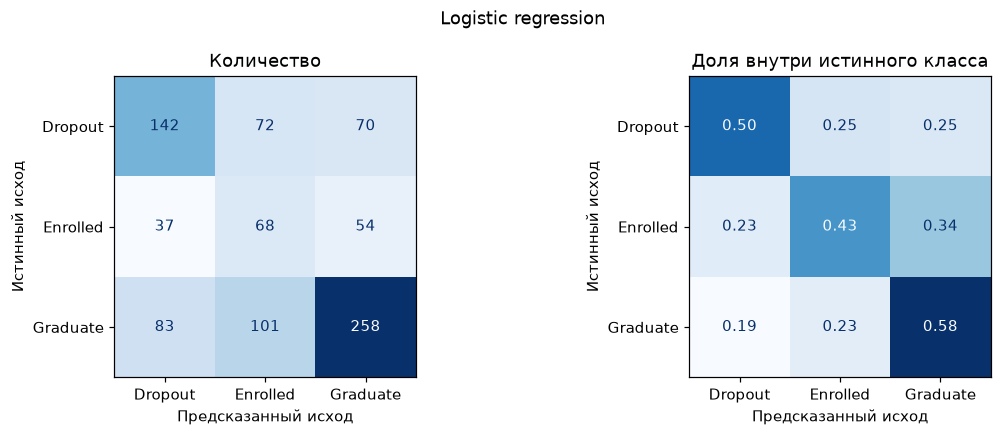


Decision tree
              precision    recall  f1-score   support

     Dropout      0.573     0.373     0.452       284
    Enrolled      0.232     0.730     0.353       159
    Graduate      0.766     0.348     0.479       442

    accuracy                          0.425       885
   macro avg      0.524     0.484     0.428       885
weighted avg      0.608     0.425     0.448       885

Balanced accuracy: 0.4837


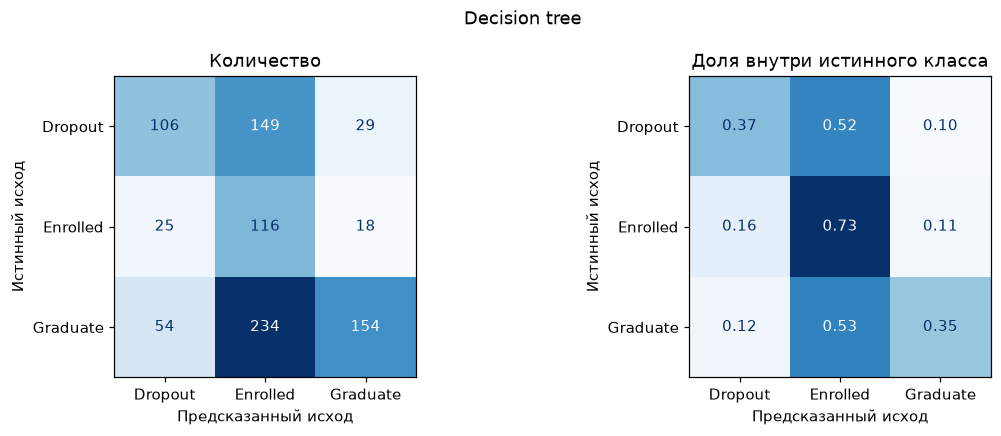


Dummy: most frequent
              precision    recall  f1-score   support

     Dropout      0.000     0.000     0.000       284
    Enrolled      0.000     0.000     0.000       159
    Graduate      0.499     1.000     0.666       442

    accuracy                          0.499       885
   macro avg      0.166     0.333     0.222       885
weighted avg      0.249     0.499     0.333       885

Balanced accuracy: 0.3333


,CV macro F1,CV F1 std,CV balanced accuracy,CV accuracy,Train macro F1,Test macro F1,...,Test accuracy,Test weighted F1,F1 Dropout,F1 Enrolled,F1 Graduate,Выбрана по CV
Model,,,,,,,,,,,,,
Logistic regression,0.5164,0.0220,0.5264,0.5499,0.5768,0.4955,...,0.5288,0.5408,0.5201,0.3400,0.6262,True
Decision tree,0.4348,0.0135,0.4704,0.4538,0.4795,0.4279,...,0.4249,0.4476,0.4520,0.3526,0.4790,False
Dummy: most frequent,0.2220,0.0002,0.3333,0.4993,0.2220,0.2221,...,0.4994,0.3327,0.0000,0.0000,0.6662,False


In [10]:
fitted_models, predictions, reports, matrices = {}, {}, {}, {}
test_rows = []
for name, estimator in models.items():
    fitted = clone(estimator).fit(X_train, y_train)
    pred = fitted.predict(X_test)
    fitted_models[name], predictions[name] = fitted, pred
    report = classification_report(
        y_test, pred, labels=CLASS_ORDER, output_dict=True, zero_division=0,
    )
    reports[name] = report
    matrices[name] = confusion_matrix(y_test, pred, labels=CLASS_ORDER)
    row = {
        "Model": name,
        "Test macro F1": f1_score(y_test, pred, average="macro"),
        "Test balanced accuracy": balanced_accuracy_score(y_test, pred),
        "Test accuracy": accuracy_score(y_test, pred),
        "Test weighted F1": f1_score(y_test, pred, average="weighted"),
    }
    for label in CLASS_ORDER:
        row[f"F1 {label}"] = report[label]["f1-score"]
    test_rows.append(row)
    print(f"\n{name}")
    print(classification_report(y_test, pred, labels=CLASS_ORDER, digits=3, zero_division=0))
    print(f"Balanced accuracy: {row['Test balanced accuracy']:.4f}")
    if name != "Dummy: most frequent":
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, normalization, title in zip(
            axes, [None, "true"], ["Количество", "Доля внутри истинного класса"]
        ):
            ConfusionMatrixDisplay.from_predictions(
                y_test, pred, labels=CLASS_ORDER, normalize=normalization,
                cmap="Blues", colorbar=False, ax=ax,
                values_format="d" if normalization is None else ".2f",
            )
            ax.set(title=title, xlabel="Предсказанный исход", ylabel="Истинный исход")
        fig.suptitle(name)
        plt.tight_layout()
        plt.show()

test_table = pd.DataFrame(test_rows).set_index("Model")
comparison = cv_table.join(test_table).copy()
comparison["Выбрана по CV"] = comparison.index == best_name
display(comparison.round(4))

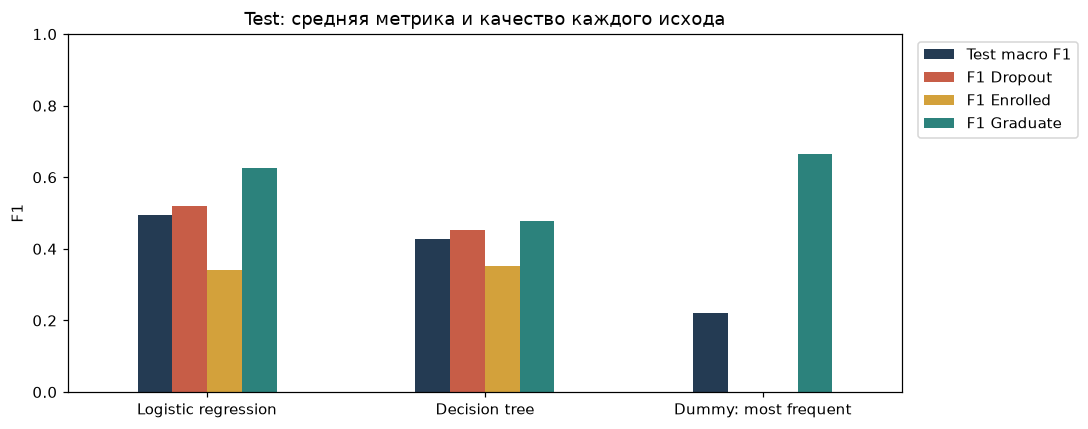

**Выбор: Logistic regression.** Средний CV macro F1 = 0.516; на test macro F1 = 0.495, balanced accuracy = 0.504. Наиболее сложный класс по test F1: **Enrolled** (F1 = 0.340). Разница CV macro F1 между моделями — 0.082; это сравнение одного протокола, а не доказательство статистически значимого превосходства.

In [11]:
# Сравнение ключевой метрики и F1 отдельных классов.
plot_cols = ["Test macro F1"] + [f"F1 {c}" for c in CLASS_ORDER]
ax = test_table.loc[list(models), plot_cols].plot.bar(
    figsize=(10, 4), rot=0, color=["#243B53", "#C75D47", "#D3A13B", "#2C827C"],
)
ax.set(ylim=(0, 1), xlabel="", ylabel="F1", title="Test: средняя метрика и качество каждого исхода")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

best_model = fitted_models[best_name]
best_report = reports[best_name]
best_cm = matrices[best_name]
weakest_class = min(CLASS_ORDER, key=lambda c: best_report[c]["f1-score"])
best_row = comparison.loc[best_name]
f1_gap = cv_table.drop(index="Dummy: most frequent")["CV macro F1"].diff().abs().max()
display(Markdown(
    f"**Выбор: {best_name}.** Средний CV macro F1 = {best_row['CV macro F1']:.3f}; "
    f"на test macro F1 = {best_row['Test macro F1']:.3f}, "
    f"balanced accuracy = {best_row['Test balanced accuracy']:.3f}. "
    f"Наиболее сложный класс по test F1: **{weakest_class}** "
    f"(F1 = {best_report[weakest_class]['f1-score']:.3f}). "
    f"Разница CV macro F1 между моделями — {f1_gap:.3f}; "
    "это сравнение одного протокола, а не доказательство статистически значимого превосходства."
))

#### 9. Что означают ошибки Dropout ↔ Graduate
* Dropout → Graduate	Пропущен риск: студент может не получить своевременное приглашение на консультацию.
* Graduate → Dropout	Ложная тревога: консультация предложена студенту, который впоследствии завершил обучение. При добровольной поддержке цена ошибки - время и ресурсы.
* Dropout → Enrolled	Тоже пропуск Dropout при стратегии «приглашать только предсказанный Dropout».
* Ошибки с Enrolled	Продолжающих обучение трудно отделить от двух конечных исходов; объединять их с Graduate или Dropout без смены постановки нельзя.
* Recall Dropout учитывает пропуски в оба других класса. Precision Dropout учитывает ложные тревоги из обоих других классов.

In [12]:
d, e, g = [CLASS_ORDER.index(c) for c in CLASS_ORDER]
error_table = pd.DataFrame([
    {"Ошибка": "Dropout → Graduate", "Количество": int(best_cm[d, g]),
     "Доля истинного класса": best_cm[d, g] / best_cm[d].sum()},
    {"Ошибка": "Dropout → Enrolled", "Количество": int(best_cm[d, e]),
     "Доля истинного класса": best_cm[d, e] / best_cm[d].sum()},
    {"Ошибка": "Graduate → Dropout", "Количество": int(best_cm[g, d]),
     "Доля истинного класса": best_cm[g, d] / best_cm[g].sum()},
])
display(error_table.round(3))
print(f"Recall Dropout: {best_report['Dropout']['recall']:.3f}")
print(f"Precision Dropout: {best_report['Dropout']['precision']:.3f}")
print("Всего реальных Dropout, пропущенных моделью:", int(best_cm[d].sum() - best_cm[d, d]))

,Ошибка,Количество,Доля истинного класса
0,Dropout → Graduate,70,0.246
1,Dropout → Enrolled,72,0.254
2,Graduate → Dropout,83,0.188


Recall Dropout: 0.500
Precision Dropout: 0.542
Всего реальных Dropout, пропущенных моделью: 142


#### 10. Использование для ранней поддержки
Базовый подход: предложить добровольную консультацию студентам с прогнозом Dropout. Ниже оценивается объём приглашений и ошибки этой стратегии на отложенной выборке. 
В рабочем процессе куратор проверяет актуальность сведений и выясняет потребности студента. Возможные предложения - академическая консультация, адаптационная помощь, информация о финансовой поддержке. Прогноз - он и есть прогноз, а не основание для наказания, отказа в обучении или ограничения возможностей. Поддержку можно запросить и без высокого модельного риска.  
Можно ранжировать по P(Dropout) и выбирать порог с учётом пропускной способности консультантов. Порог следует подбирать на validation/OOF прогнозах train, не на test. В этой части порог не оптимизируем. Вероятность модели - оценка, а не доказанная индивидуальная вероятность; после class_weight особенно важна проверка калибровки.  
Пол, гражданство, возраст и семейные характеристики способны отражать различия доступа к образованию. Перед применением нужны проверка ошибок по группам, обоснование необходимости таких признаков, защита доступа и проверка качества на новых когортах. Удаление одного чувствительного поля не устраняет его косвенные заместители. Успех поддержки нужно измерять отдельно: классификация не доказывает, что консультация изменит исход.

In [13]:
best_pred = predictions[best_name]
invite = best_pred == "Dropout"
actual_dropout = y_test.to_numpy() == "Dropout"
invited_count = int(invite.sum())
support_summary = pd.Series({
    "Студентов в test": len(y_test),
    "Предложений консультации": invited_count,
    "Из приглашённых: фактический Dropout": int((invite & actual_dropout).sum()),
    "Из приглашённых: другой фактический исход": int((invite & ~actual_dropout).sum()),
    "Фактических Dropout без приглашения": int((~invite & actual_dropout).sum()),
}, name="Количество")
display(support_summary.to_frame())
print(f"Доля приглашений: {invite.mean():.1%}")
print(f"Доля найденных Dropout: {(invite & actual_dropout).sum() / actual_dropout.sum():.1%}")

,Количество
Студентов в test,885
Предложений консультации,262
Из приглашённых: фактический Dropout,142
Из приглашённых: другой фактический исход,120
Фактических Dropout без приглашения,142


Доля приглашений: 29.6%
Доля найденных Dropout: 50.0%


#### 11. Дополнительно: ROC-AUC one-vs-rest
Для каждого исхода рассматриваем «этот класс против двух остальных», используя вероятности, затем усредняем AUC с одинаковым весом. Порядок столбцов predict_proba берётся из classes_, а не вручную. ROC-AUC характеризует ранжирование и не заменяет F1/Recall при конкретном решении о классе.

In [14]:
auc_rows = []
for name in ["Logistic regression", "Decision tree"]:
    estimator = fitted_models[name]
    probabilities = estimator.predict_proba(X_test)
    class_labels = estimator.classes_
    assert np.allclose(probabilities.sum(axis=1), 1)
    row = {"Model": name,
           "Macro ROC-AUC OvR": roc_auc_score(
               y_test, probabilities, labels=class_labels, multi_class="ovr", average="macro",
           )}
    for column_index, label in enumerate(class_labels):
        row[f"AUC {label}"] = roc_auc_score(y_test.eq(label), probabilities[:, column_index])
    auc_rows.append(row)
display(pd.DataFrame(auc_rows).set_index("Model").round(4))

,Macro ROC-AUC OvR,AUC Dropout,AUC Enrolled,AUC Graduate
Model,,,,
Logistic regression,0.6937,0.7351,0.6356,0.7104
Decision tree,0.6582,0.6794,0.6086,0.6866


#### 12. Проверки и итог
Allowlist применяется до split. Каждая модель обучается на одинаковых данных. Предобработка обучается внутри CV и финального train, test не задаёт категории или масштабы. Проверки ниже контролируют фактически обученный pipeline.

In [15]:
for name in ["Logistic regression", "Decision tree"]:
    fitted = fitted_models[name]
    prep = fitted.named_steps["preprocessor"]
    assert list(prep.feature_names_in_) == ALLOWLIST
    encoder = prep.named_transformers_["cat"].named_steps["onehot"]
    for feature, categories in zip(CAT_FEATURES, encoder.categories_):
        assert set(categories) == set(X_train[feature].dropna().unique())
    scaler = prep.named_transformers_["num"].named_steps["scaler"]
    assert np.all(np.asarray(scaler.n_samples_seen_) == len(X_train))
    assert set(fitted.classes_) == set(CLASS_ORDER)
    assert matrices[name].sum() == len(X_test)
    assert np.isclose(
        test_table.loc[name, "Test balanced accuracy"], reports[name]["macro avg"]["recall"]
    )
    print(f"{name}: после кодирования {len(prep.get_feature_names_out())} признаков; проверки пройдены")

lr = fitted_models["Logistic regression"].named_steps["model"]
print("Итераций логистической регрессии:", lr.n_iter_)
assert max(lr.n_iter_) < lr.max_iter

Logistic regression: после кодирования 230 признаков; проверки пройдены
Decision tree: после кодирования 230 признаков; проверки пройдены
Итераций логистической регрессии: [138]


В запуске логистическая регрессия получила CV macro F1 0,516, test macro F1 0,496 (дерево — 0,428, Dummy — 0,222 на test). Её test balanced accuracy — 0,501. Самый слабый класс — Enrolled: F1 0,340. При приглашении только предсказанного Dropout модель находит 142 из 284 фактических Dropout (Recall 50%) и пропускает 142. Из 262 приглашения 120 приходятся на другие исходы. Поэтому это ограниченный baseline, и такой прогноз не может быть единственным каналом к поддержке студента.  
Результаты относятся к 18 разрешённым признакам и не сопоставимы напрямую с публикациями, использующими результаты семестров или поздние статусы оплаты. Для следующей части уместны подбор гиперпараметров внутри train, анализ устойчивости по фолдам и настройка правила приглашения на консультацию; текущий test после просмотра не следует многократно использовать для разработки.